In [54]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict,Literal

In [55]:
class QuadState(TypedDict):

    a= int
    b = int
    c= int

    equation=str

    discri=float

    result=str

In [56]:
def show_equation(state: QuadState):
    equation=f'{state["a"]}x2{state["b"]}x{state["c"]}'

    return {'equation':equation}


def calcu_descri(state:QuadState):

    discri=state["b"]**2 - (4*state["a"]*state["c"])

    return {"discri":discri}




In [57]:
def real_roots(state: QuadState):
    root1= (-state["b"]+state["discri"]**0.5)/(2*state["a"])
    root2=(-state["b"]-state["discri"]**0.5)/(2*state["a"])

    result=f'the roots are {root1} and {root2}'


    return {'result':result}

In [ ]:
def reapeted_roots(state: QuadState):
    root= (-state["b"])/(2*state["a"])

    result= f'the root are {root}'

    return {'result':result}

In [59]:
def no_roots(state: QuadState):
    result=f'there is no real roots'

    return {'result':result}


In [60]:
def check_condition(state: QuadState) -> Literal['real_roots','reapeted_roots','no_roots']:
    if state['discri'] >0:
        return 'real_roots'

    elif state['discri']==0:
        return 'reapeted_roots'

    else:
        return 'no_roots'

In [61]:
graph=StateGraph(QuadState)

graph.add_node('show_equation',show_equation)
graph.add_node('calcu_descri',calcu_descri)
graph.add_node('real_roots',real_roots)
graph.add_node('reapeted_roots',reapeted_roots)
graph.add_node('no_roots',no_roots)

graph.add_edge(START,'show_equation')
graph.add_edge("show_equation",'calcu_descri')
graph.add_edge('calcu_descri',END)



graph.add_conditional_edges('calcu_descri',check_condition)
graph.add_edge('real_roots', END)
graph.add_edge('reapeted_roots', END)
graph.add_edge('no_roots', END)



In [62]:
workflow=graph.compile()


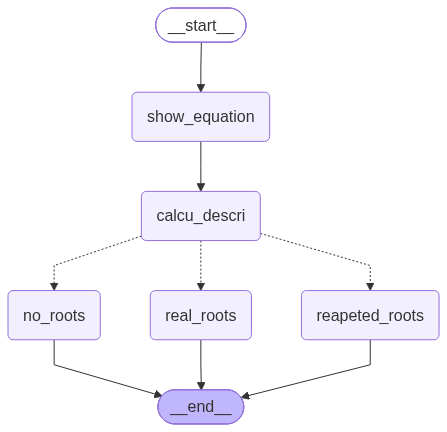

In [63]:
workflow

In [64]:
inital_state={
    'a':2,
    'b':5,
    'c':9
}
workflow.invoke(inital_state)

KeyError: 'a'